In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  # Add this
    print_overlap_matrix, 
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
numb = "46"
tumor = "t"+numb

In [3]:
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values
#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [4]:
bincounts[bincounts["chrom"]=="chr19"]

,chrom,loc.start,loc.end,abstart,abend,AAAACCAAACTTAGAGA,AAAACCAAAGTAGTTCT,AAAACCAAATCCCGTCT,AAAACCAACAAGACAAT,AAAACCAACAAGATTGG,...,TTGGACGTTTTACGAAT,TTGGGATAAACCATACG,TTTCGAGTTTTACAATA,TTTCGATGGTGCGAATC,TTTCGATTCGGCCGTTC,TTTTGGAGAATTTAAGC,TTTTGGATGAGGGTAGC,TTTTGGGTTTTACTAGA,TTTTGGTGCAGGACTTC,TTTTGGTTTAGTAGACT
106,chr19,0,8508703,2659444323,2667953026,259,100,87,230,5,...,276,8,297,301,81,101,82,3,26,71
107,chr19,9181554,23863753,2668625877,2683308076,717,253,333,421,2,...,694,139,708,527,506,219,202,131,551,266
108,chr19,24449630,30400661,2683893953,2689844984,338,50,87,77,30,...,214,42,278,150,306,122,57,136,365,110
109,chr19,30952034,37745190,2690396357,2697189513,661,123,200,222,45,...,430,76,648,291,634,291,253,185,1129,208
110,chr19,38365091,51427251,2697809414,2710871574,942,185,349,372,32,...,684,189,802,331,488,227,139,186,915,267
111,chr19,51989553,52549123,2711433876,2711993446,39,7,16,17,1,...,25,7,32,3,65,1,1,2,18,12
112,chr19,53123695,58522984,2712568018,2717967307,286,83,111,153,11,...,69,86,349,101,295,79,37,88,281,69


In [5]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_non_random_seeding_A.txt", sep="\t")
a_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t")
equi_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt", sep="\t")
#C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [6]:
A_df.head()

,cell,population
0,AAAACCCTGTTTGATTA,A111
1,AAAACCGAGGTAACAAT,A111
2,AAAACCTGGCGATCAGA,A111
3,AAAACCTTCCCACTATC,A111
4,AAAATGAAGATTCAAGT,A111


In [7]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }


A111
A112
A121
A1221
A1222
A2


In [8]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B1
B21
B22


In [9]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C1
C211
C212
C22


In [10]:
D_dict = {}
for cluster in D_df['population'].unique():
    print(cluster)
    cells_in_cluster = D_df[D_df['population'] == cluster]['cell'].tolist()
    D_dict[cluster] = {
        'cells': cells_in_cluster
    }

D11
D12
D2


In [11]:
# equi_dict = {}
# for cluster in equi_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = equi_df[equi_df['population'] == cluster]['cell'].tolist()
#     equi_dict[cluster] = {
#         'cells': cells_in_cluster
#     }

In [12]:
#overlap_df = print_overlap_matrix(A_dict, equi_dict, name1="WGS bins - ", name2="equi-partitioned bins -")

In [13]:
# new_order = []
# for col in overlap_df.columns:
#     #Find the index of the maximum value in the column
#     max_index = overlap_df[col].idxmax()
#     if max_index not in new_order:
#         new_order.append(max_index)

# for row in overlap_df.index:
#     if row not in new_order:
#         new_order.append(row)
# new_order_dict = {k: A_dict[k] for k in new_order}
    

In [14]:
cluster_counts = bincounts[["chrom", "abstart", "abend"]].copy()
for cluster in A_dict.keys():
    cells_in_cluster = A_dict[cluster]['cells']
    cluster_counts[cluster] = bincounts[cells_in_cluster].sum(axis=1)

In [15]:
cluster_counts.to_csv(f"../data/{tumor}/{tumor}_cluster_counts_A_WGS_bins.txt", sep="\t", index=False)

In [16]:
#overlap_df = plot_overlap_matrix_figure(A_dict, equi_dict, name1="WGS bins", name2="equi-partitioned bins")


Overlap Matrix (A rows vs B cols):
Pop           B1     B21     B22
A111           0       3     248
A112           0      21     424
A121           1      72      21
A1221          0      54      18
A1222          0     474       8
A2           283       0       0


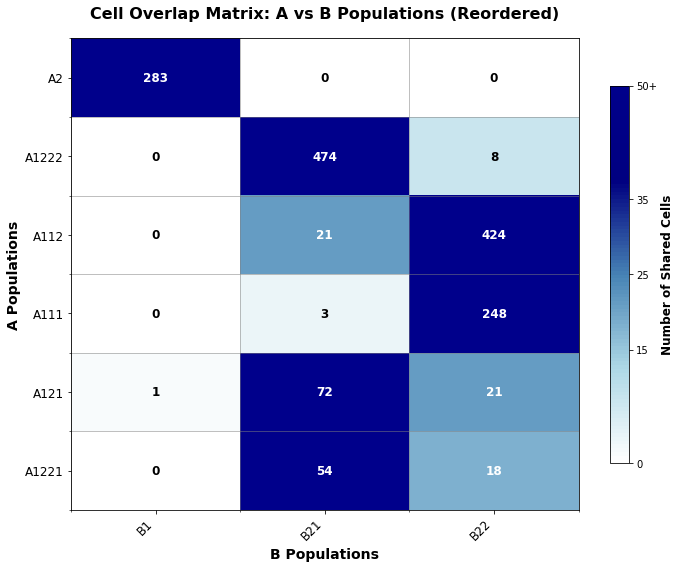

In [17]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")


Overlap Matrix (A rows vs B cols):
Pop           C1    C211    C212     C22
A111           0       4     247       0
A112           0     428       8       9
A121           1      29       5      59
A1221          0       4      28      40
A1222          0       7       1     474
A2           283       0       0       0


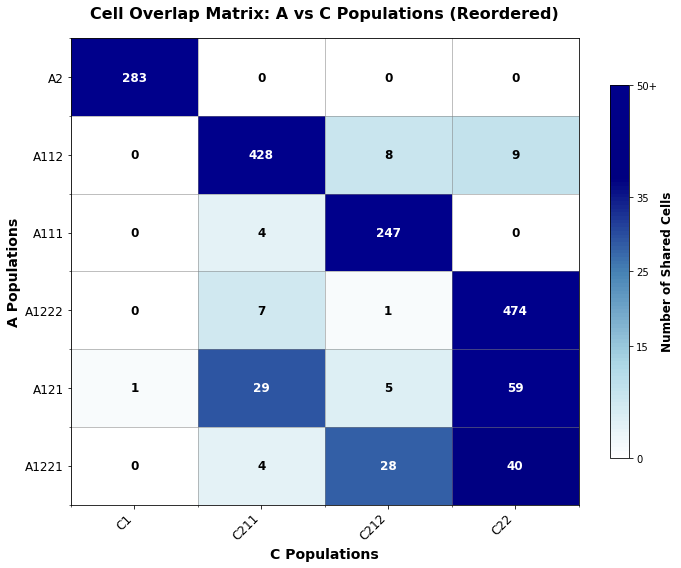

In [18]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")


Overlap Matrix (A rows vs B cols):
Pop           C1    C211    C212     C22
B1           284       0       0       0
B21            0      32      19     573
B22            0     440     270       9


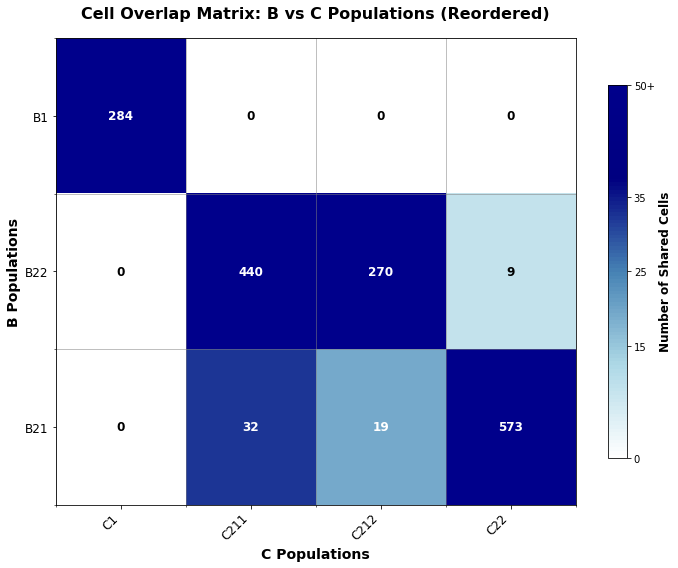

In [19]:
overlap_df = plot_overlap_matrix_figure(B_dict, C_dict, name1="B", name2="C")


Overlap Matrix (A rows vs B cols):
Pop          D11     D12      D2
C1             0       0     284
C211          30     442       0
C212          18     271       0
C22          572      10       0


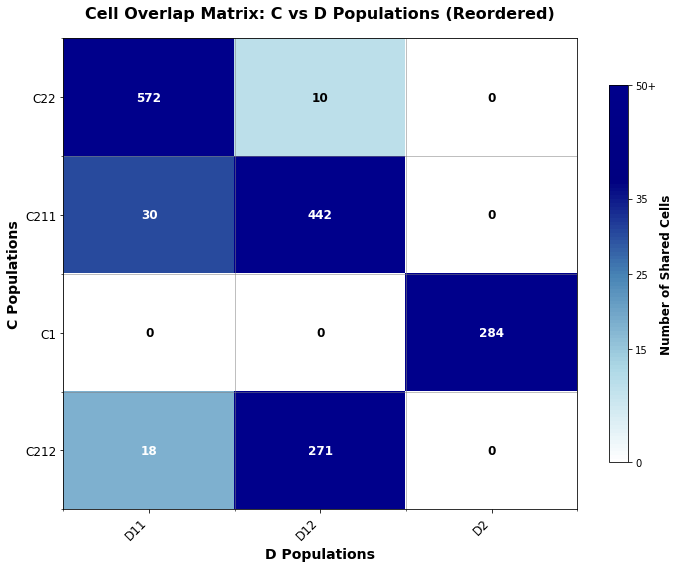

In [20]:
overlap_df = plot_overlap_matrix_figure(C_dict, D_dict, name1="C", name2="D")


Overlap Matrix (A rows vs B cols):
Pop           C1    C211    C212     C22
A111           0       4     247       0
A112           0     428       8       9
A121           1      29       5      59
A1221          0       4      28      40
A1222          0       7       1     474
A2           283       0       0       0


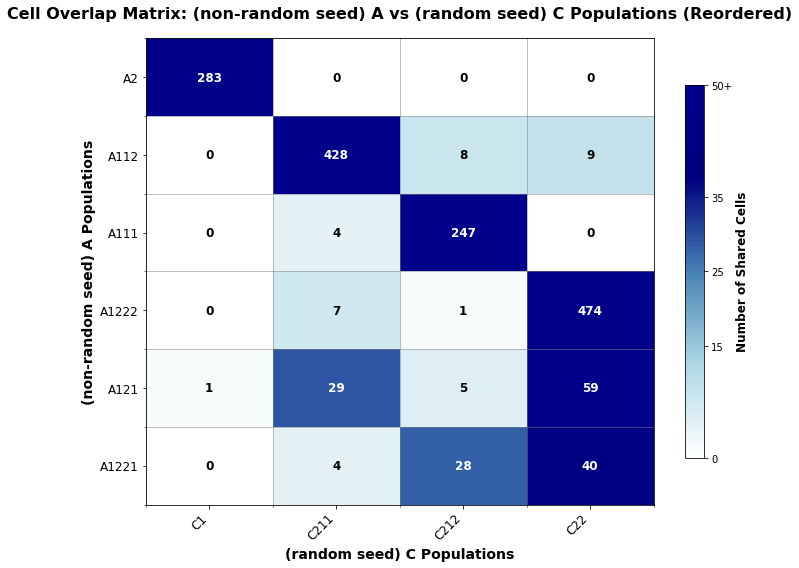

In [27]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict,  name1="(non-random seed) A", name2="(random seed) C")

In [28]:
#overlap_df = plot_overlap_matrix_figure(A_dict, D_dict,  name1="(non-random seed) A", name2="(random seed) D")

In [29]:
#normalized_overlap_df

In [30]:
def new_overlap_matrix(overlap_df, name1 = "Pop1", name2 = "Pop2", title=None):
    pop1_names = overlap_df.index.tolist()
    pop2_names = overlap_df.columns.tolist()
    row_sums = overlap_df.sum(axis=1)
    col_sums = overlap_df.sum(axis=0)

    # min_matrix[i, j] = min(row_sums[i], col_sums[j])
    min_matrix = np.minimum(row_sums.values[:, None], col_sums.values[None, :])

    normalized_overlap_df = overlap_df / min_matrix
    overlap_matrix = normalized_overlap_df.values

    # Create custom colormap for better visualization
    colors = ['white', 'lightblue', 'steelblue', 'navy', 'darkblue']
    n_bins = 100
    cmap = LinearSegmentedColormap.from_list('custom_blues', colors, N=n_bins)

    # Create normalized matrix for color mapping
    color_matrix = np.copy(overlap_matrix)

    # Create the figure
    fig, ax = plt.subplots(figsize=(10,8))

    # Create the main heatmap with custom color scaling
    im = ax.imshow(color_matrix, cmap=cmap, aspect='auto')

    # Add text annotations with cell counts
    for i in range(len(pop1_names)):
        for j in range(len(pop2_names)):
            text = round(overlap_matrix[i, j],2)
            
            # Determine text color based on background
            if overlap_matrix[i, j] < 15:
                text_color = 'black'
            elif overlap_matrix[i, j] < 30:
                text_color = 'white'
            else:
                text_color = 'white'
                
            ax.text(j, i, text, ha='center', va='center', 
                    fontsize=12, fontweight='bold', color=text_color)

    # Customize main heatmap
    ax.set_xticks(range(len(pop2_names)))
    ax.set_yticks(range(len(pop1_names)))
    ax.set_xticklabels(pop2_names, rotation=45, ha='right', fontsize=12)
    ax.set_yticklabels(pop1_names, fontsize=12)
    ax.set_xlabel(f'{name2} Populations', fontsize=14, fontweight='bold')
    ax.set_ylabel(f'{name1} Populations', fontsize=14, fontweight='bold')

    # Add gridlines
    ax.set_xticks(np.arange(len(pop2_names)+1)-0.5, minor=True)
    ax.set_yticks(np.arange(len(pop1_names)+1)-0.5, minor=True)
    ax.grid(which='minor', color='gray', linestyle='-', linewidth=1, alpha=0.5)

    # Add colorbar with custom labels
    cbar = plt.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('overlap measure', fontsize=12, fontweight='bold')

    # Set custom colorbar ticks
    cbar_ticks = [0, 0.25, 0.5, 0.75, 1]
    cbar_labels = ['0', '0.25', '0.5', '0.75', '1']
    cbar.set_ticks(cbar_ticks)
    cbar.set_ticklabels(cbar_labels)

    # Main title
    if title is None:
        title = f'Cell Overlap Matrix: {name1} vs {name2} Populations (Reordered)'
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)

    plt.tight_layout()
    plt.show()

    return normalized_overlap_df

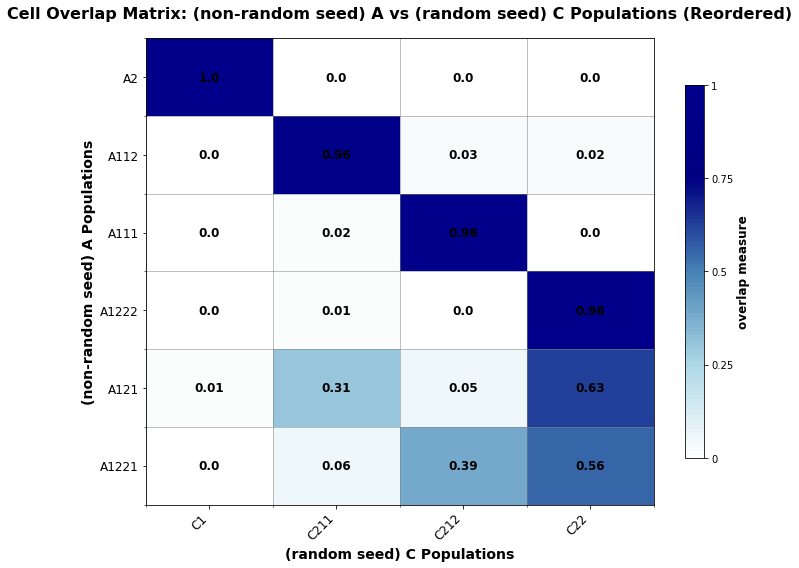

In [31]:
normalized_overlap_df = new_overlap_matrix(overlap_df, name1="(non-random seed) A", name2="(random seed) C")

In [26]:
stop

NameError: name 'stop' is not defined

In [ ]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()
all_data_no_WGS = data_no_WGS[cells].copy()

In [ ]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



In [ ]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)
B_df["normal_population"] = (B_df['population'] == normal_B)
C_df["normal_population"] = (C_df['population'] == normal_C)
D_df["normal_population"] = (D_df['population'] == normal_D)

In [ ]:
# A_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t", index = False)
# B_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t", index = False)
# C_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t", index = False)
# D_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t", index = False)

In [ ]:
# A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
# A_dict = {}
# for cluster in A_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
#     A_dict[cluster] = {
#         'cells': cells_in_cluster
#     }
# avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
# relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)

In [ ]:
data_lengths = data["abend"] - data["abstart"]

In [ ]:
plot_uniformity_histograms_nice(
    all_data, 
    C_dict, 
    data_lengths, 
    uniformity_data=None,  # Optional: will compute if not provided
    title_prefix="Populations from WGS bins - ", 
    figsize=(12, 8)
)

In [ ]:
plot_uniformity_histograms_nice(
    all_data, 
    A_dict, 
    data_lengths, 
    uniformity_data=None,  # Optional: will compute if not provided
    title_prefix="Populations from WGS bins - ", 
    figsize=(12, 8)
)

In [ ]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

In [ ]:
relative_counts_A

In [ ]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

In [ ]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")

In [ ]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [ ]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = f"../data/{tumor}/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv(f"/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/{tumor}/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

In [ ]:
hap_count_df.head()

In [ ]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))

In [ ]:
example = list(A_dict.keys())[1]

In [ ]:
# # Example usage for A211 with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,  # or use ploidy_results_A[example]['optimal_multiplier']
#     local_m=3.1,   # pick from ploidy_results_A[example]['local_minima']
#     pop_col=f'{example}_ratio'
# )

In [ ]:
#Get all cells in example
example_cells = A_dict[example]['cells']
#Filter hap_count_df for these cells
example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
example_hap_ratio['hap_ratio'] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
example_hap_ratio['folded'] = example_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information    
example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])

In [ ]:
example_hap_ratio["hap_ratio"].hist(bins=100, range=(0,1))

In [ ]:
# plot the folded allele frequency along the genome
example_hap_ratio_sorted = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(example_hap_ratio_sorted['abspos'], example_hap_ratio_sorted['folded'], s=1, alpha=0.8)
plt.xlabel('Chromosome')
plt.ylabel('Allele Frequency')
plt.title('Allele Frequency Across Genome for Population ' + example)
# Add vertical lines for chromosome boundaries
chrom_boundaries = example_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = example_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(example_hap_ratio_sorted['abspos'].min(), example_hap_ratio_sorted['abspos'].max())
plt.show()

In [ ]:
hap_df_dict = {}
hap_summary_df = pd.DataFrame()
for pop_name in C_dict.keys():
    #Get all cells in example
    example_cells = C_dict[pop_name]['cells']
    #Filter hap_count_df for these cells
    example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
    # compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
    example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
    example_hap_ratio['hap_ratio_'+pop_name] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
    example_hap_ratio.rename(columns={'hap_count': 'hap_count_'+pop_name, 'Total': 'Total_'+pop_name}, inplace=True)
    example_hap_ratio['folded_'+pop_name] = example_hap_ratio['hap_ratio_'+pop_name].apply(lambda x: min(x, 1-x))
    # Add chromosome information    
    example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])
    example_hap_ratio = example_hap_ratio[["bin", "abspos", "chrom", 'hap_ratio_'+pop_name, 'folded_'+pop_name, 'hap_count_'+pop_name, 'Total_'+pop_name]]
    hap_df_dict[pop_name] = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
    example_hap_ratio['hap_ratio_'+pop_name].hist(bins=100, range=(0,1))
    plt.axvline(x=0.5, color='black', linestyle='--', label='balanced allele frequency')
    plt.axvline(x=0.33, color='blue', linestyle='--', label='1:2 allele frequency')
    plt.axvline(x=0.25, color='blue', linestyle='--')
    plt.axvline(x=0.01, color='red', linestyle='--', label='Loss of heterozygosity (LoH)')
    plt.axvline(x=0.99, color='red', linestyle='--')
    plt.legend()
    plt.title(f"Allele Frequency Histogram for Population {pop_name}")
    plt.xlabel('Allele Frequency')
    plt.ylabel('Count')
    plt.show()
    if hap_summary_df.empty:
        hap_summary_df = example_hap_ratio.sort_values(by=['chrom', 'abspos']).copy()
    else:
        hap_summary_df = hap_summary_df.merge(
            example_hap_ratio,
            on=['bin', 'abspos', 'chrom'],
            suffixes=('', f'_{pop_name}')
        )


In [ ]:
hap_df_dict = {}
hap_summary_df = pd.DataFrame()
for pop_name in A_dict.keys():
    #Get all cells in example
    example_cells = A_dict[pop_name]['cells']
    #Filter hap_count_df for these cells
    example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
    # compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
    example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
    example_hap_ratio['hap_ratio_'+pop_name] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
    example_hap_ratio.rename(columns={'hap_count': 'hap_count_'+pop_name, 'Total': 'Total_'+pop_name}, inplace=True)
    example_hap_ratio['folded_'+pop_name] = example_hap_ratio['hap_ratio_'+pop_name].apply(lambda x: min(x, 1-x))
    # Add chromosome information    
    example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])
    example_hap_ratio = example_hap_ratio[["bin", "abspos", "chrom", 'hap_ratio_'+pop_name, 'folded_'+pop_name, 'hap_count_'+pop_name, 'Total_'+pop_name]]
    hap_df_dict[pop_name] = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
    example_hap_ratio['hap_ratio_'+pop_name].hist(bins=100, range=(0,1))
    plt.title(f"Allele Frequency Histogram for Population {pop_name}")
    plt.xlabel('Allele Frequency')
    plt.ylabel('Count')
    plt.show()
    if hap_summary_df.empty:
        hap_summary_df = example_hap_ratio.sort_values(by=['chrom', 'abspos']).copy()
    else:
        hap_summary_df = hap_summary_df.merge(
            example_hap_ratio,
            on=['bin', 'abspos', 'chrom'],
            suffixes=('', f'_{pop_name}')
        )


In [ ]:
hap_summary_df

In [ ]:
hap_summary_df.to_csv(f"../data/{tumor}/{tumor}_haplotype_summary_by_population_A.txt", sep="\t", index=False)

In [ ]:
normal_A

In [ ]:
#Get all cells in A1
normal_cells = A_dict[normal_A]['cells']
#Filter hap_count_df for these cells
normal_hap_df = hap_count_df[hap_count_df['cell'].isin(normal_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
normal_hap_ratio = normal_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
normal_hap_ratio['hap_ratio'] = normal_hap_ratio['hap_count'] / normal_hap_ratio['Total']
normal_hap_ratio['folded'] = normal_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
normal_hap_ratio["chrom"] = normal_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])

In [ ]:
# plot the folded allele frequency along the genome
normal_hap_ratio_sorted = normal_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(normal_hap_ratio_sorted['abspos'], normal_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over normal cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = normal_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = normal_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(normal_hap_ratio_sorted['abspos'].min(), normal_hap_ratio_sorted['abspos'].max())
plt.show()

In [ ]:
A_df.head()

In [ ]:
#Get all tumor cells in (not A1)
tumor_cells = A_df[A_df['population'] != normal_A]['cell'].tolist()
#Filter hap_count_df for these cells
tumor_hap_df = hap_count_df[hap_count_df['cell'].isin(tumor_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
tumor_hap_ratio = tumor_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
tumor_hap_ratio['hap_ratio'] = tumor_hap_ratio['hap_count'] / tumor_hap_ratio['Total']
tumor_hap_ratio['folded'] = tumor_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
tumor_hap_ratio["chrom"] = tumor_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])


In [ ]:
# plot the folded allele frequency along the genome
tumor_hap_ratio_sorted = tumor_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(tumor_hap_ratio_sorted['abspos'], tumor_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over tumor cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(tumor_hap_ratio_sorted['abspos'].min(), tumor_hap_ratio_sorted['abspos'].max())
plt.show()

In [ ]:
# # Example usage for example with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,
#     local_m=3.1,
#     pop_col=example + '_ratio',
#     hap_count_df=hap_count_df,
#     cells=A_dict[example]['cells']
# )

In [ ]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [ ]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [ ]:
# # reorder A_dict based on new order from overlap_df index
# A_dict_reordered = {k: A_dict[k] for k in overlap_df.index}

In [ ]:
# Add to your imports at the top:



In [ ]:
# Create population summary table
summary_rows = []

for pop_name in A_dict.keys():
    # Get cells for this population
    pop_cells = A_dict[pop_name]['cells']
    num_cells = len(pop_cells)
    
        

    # Calculate average read count per cell for this population
    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells
    
    # Get relative counts (already computed in relative_counts_A)
    relative_count = relative_counts_A[pop_name].mean()

    if pop_name!= normal_A:
        results = ploidy_results_A[pop_name]
        local_minima = results['local_minima']
        target_m = 2 * relative_count
        #pick two best minima
        optimal_m = results['optimal_multiplier']
    
        # Find the local minimum closest to the global minimum (excluding the global minimum itself)
        other_minima = [m for m, _ in local_minima if m != optimal_m]
        
        if other_minima:
            # Find the minimum distance to the global minimum
            min_distance = min(abs(m - optimal_m) for m in other_minima)
            # Get all minima at this minimum distance
            closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
            # Pick the smaller one if there are ties
            second_best_m = min(closest_minima)
    # Get relative ploidy from ploidy_results_A (if it exists, otherwise it's the normal so use 1.0)
    if pop_name in ploidy_results_A:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0  # Normal population
        second_best_m = 2.0
    
    # Add (normal) label if this is the normal population
    display_name = f"{pop_name} (normal)" if pop_name == normal_A else pop_name
    
    summary_rows.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_count,
        'best_ploidy': relative_ploidy,
        'second_best' : second_best_m
    })

# Create DataFrame
population_summary_table = pd.DataFrame(summary_rows)

population_summary_table["rel_counts*2"] = population_summary_table["relative_counts"] * 2
#display it nicely
population_summary_table

In [ ]:
population_summary_table.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t", index=False)

In [ ]:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

In [ ]:
# Get all population ratio columns (excluding normal population) for B
pop_ratio_cols_B = [col for col in ratios_B.columns if col.endswith('_ratio') and col != f"{normal_B}_ratio"]

ploidy_results_B = {}
profile_dfs_B = {}

print(f"Normal population: {normal_B}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_B]}")

for pop_col in pop_ratio_cols_B:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")

    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_B,
        relative_counts_B,
        pop_col,
        m_range=[1.5, 6],
        step_size=0.1,
        find_local_minima=True,
        window_size=2
    )

    ploidy_results_B[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima
    }
    profile_dfs_B[pop_name] = results_df

    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")

In [ ]:
# Get all population ratio columns (excluding normal population) for C
pop_ratio_cols_C = [col for col in ratios_C.columns if col.endswith('_ratio') and col != f"{normal_C}_ratio"]

ploidy_results_C = {}
profile_dfs_C = {}

print(f"Normal population: {normal_C}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_C]}")

for pop_col in pop_ratio_cols_C:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")

    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_C,
        relative_counts_C,
        pop_col,
        m_range=[1.5, 6],
        step_size=0.1,
        find_local_minima=True,
        window_size=2
    )

    ploidy_results_C[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima
    }
    profile_dfs_C[pop_name] = results_df

    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")

In [ ]:
# Get all population ratio columns (excluding normal population) for D
pop_ratio_cols_D = [col for col in ratios_D.columns if col.endswith('_ratio') and col != f"{normal_D}_ratio"]

ploidy_results_D = {}
profile_dfs_D = {}

print(f"Normal population: {normal_D}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_D]}")

for pop_col in pop_ratio_cols_D:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")

    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_D,
        relative_counts_D,
        pop_col,
        m_range=[1.5, 6],
        step_size=0.1,
        find_local_minima=True,
        window_size=2
    )

    ploidy_results_D[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima
    }
    profile_dfs_D[pop_name] = results_df

    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")

In [ ]:
# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

print("=== Creating Copy Number Heatmaps ===")

heatmap_df_B, cell_mapping_B, boundaries_B, segment_info_B = create_copy_number_matrix_fast(
    all_data,
    B_dict,
    ratios_B,
    {f"{pop}_ratio": ploidy_results_B[pop]['optimal_multiplier'] for pop in ploidy_results_B.keys()},
    normal_B
)

print(f"Heatmap B matrix dimensions: {heatmap_df_B.shape[0]} segments × {heatmap_df_B.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_B,
    boundaries_B,
    segment_info_B,
    title="Copy Number Heatmap: Population Set B"
)


heatmap_df_C, cell_mapping_C, boundaries_C, segment_info_C = create_copy_number_matrix_fast(
    all_data,
    C_dict,
    ratios_C,
    {f"{pop}_ratio": ploidy_results_C[pop]['optimal_multiplier'] for pop in ploidy_results_C.keys()},
    normal_C
)

print(f"Heatmap C matrix dimensions: {heatmap_df_C.shape[0]} segments × {heatmap_df_C.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_C,
    boundaries_C,
    segment_info_C,
    title="Copy Number Heatmap: Population Set C"
)


heatmap_df_D, cell_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast(
    all_data,
    D_dict,
    ratios_D,
    {f"{pop}_ratio": ploidy_results_D[pop]['optimal_multiplier'] for pop in ploidy_results_D.keys()},
    normal_D
)

print(f"Heatmap D matrix dimensions: {heatmap_df_D.shape[0]} segments × {heatmap_df_D.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_D,
    boundaries_D,
    segment_info_D,
    title="Copy Number Heatmap: Population Set D"
)

In [ ]:
# Create population summary table for B
summary_rows_B = []

for pop_name in B_dict.keys():
    pop_cells = B_dict[pop_name]['cells']
    num_cells = len(pop_cells)

    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells

    relative_count = 2*relative_counts_B[pop_name]

    if pop_name != normal_B:
        results = ploidy_results_B[pop_name]
        local_minima = results['local_minima']
        optimal_m = results['optimal_multiplier']

        other_minima = [m for m, _ in local_minima if m != optimal_m]

        if other_minima:
            min_distance = min(abs(m - relative_count) for m in other_minima)
            closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
            second_best_m = min(closest_minima)
        else:
            second_best_m = optimal_m

    if pop_name in ploidy_results_B:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0
        second_best_m = 2.0

    display_name = f"{pop_name} (normal)" if pop_name == normal_B else pop_name

    summary_rows_B.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_counts_B[pop_name],
        'best_ploidy': relative_ploidy,
        'second_best': second_best_m
    })

population_summary_table_B = pd.DataFrame(summary_rows_B)
population_summary_table_B["rel_counts*2"] = population_summary_table_B["relative_counts"] * 2
population_summary_table_B

In [ ]:
# Create population summary table for C
summary_rows_C = []

for pop_name in C_dict.keys():
    pop_cells = C_dict[pop_name]['cells']
    num_cells = len(pop_cells)

    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells

    relative_count = 2*relative_counts_C[pop_name]
    
    if pop_name != normal_C:
        results = ploidy_results_C[pop_name]
        local_minima = results['local_minima']
        optimal_m = results['optimal_multiplier']

        other_minima = [m for m, _ in local_minima if m != optimal_m]

        if other_minima:
            min_distance = min(abs(m - relative_count) for m in other_minima)
            closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
            second_best_m = min(closest_minima)
        else:
            second_best_m = optimal_m
        print(pop_name)
        print(local_minima)
        print(optimal_m)
        print(relative_count)
        print(second_best_m)
    if pop_name in ploidy_results_C:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0
        second_best_m = 2.0

    display_name = f"{pop_name} (normal)" if pop_name == normal_C else pop_name

    summary_rows_C.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_counts_C[pop_name],
        'best_ploidy': relative_ploidy,
        'second_best': second_best_m
    })

population_summary_table_C = pd.DataFrame(summary_rows_C)
population_summary_table_C["rel_counts*2"] = population_summary_table_C["relative_counts"] * 2
population_summary_table_C

In [ ]:
# Create population summary table for D
summary_rows_D = []

for pop_name in D_dict.keys():
    pop_cells = D_dict[pop_name]['cells']
    num_cells = len(pop_cells)

    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells

    relative_count = 2*relative_counts_D[pop_name]

    if pop_name != normal_D:
        results = ploidy_results_D[pop_name]
        local_minima = results['local_minima']
        optimal_m = results['optimal_multiplier']

        other_minima = [m for m, _ in local_minima if m != optimal_m]

        if other_minima:
            min_distance = min(abs(m - relative_count) for m in other_minima)
            closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
            second_best_m = min(closest_minima)
        else:
            second_best_m = optimal_m

    if pop_name in ploidy_results_D:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0
        second_best_m = 2.0

    display_name = f"{pop_name} (normal)" if pop_name == normal_D else pop_name

    summary_rows_D.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_counts_D[pop_name],
        'best_ploidy': relative_ploidy,
        'second_best': second_best_m
    })

population_summary_table_D = pd.DataFrame(summary_rows_D)
population_summary_table_D["rel_counts*2"] = population_summary_table_D["relative_counts"] * 2
population_summary_table_D

In [ ]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    relative_count = 2*relative_counts_A[pop_name]
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - relative_count) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [ ]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_B.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_B[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    relative_count = 2*relative_counts_B[pop_name]
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - relative_count) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_B[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=B_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [ ]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_C.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_C[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    relative_count = 2*relative_counts_C[pop_name]
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - relative_count) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_C[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=C_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [ ]:
population_summary_table_B.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_B.txt", sep="\t", index=False)
population_summary_table_C.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_C.txt", sep="\t", index=False)
population_summary_table_D.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_D.txt", sep="\t", index=False)